## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [2]:
import pickle

with open('all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

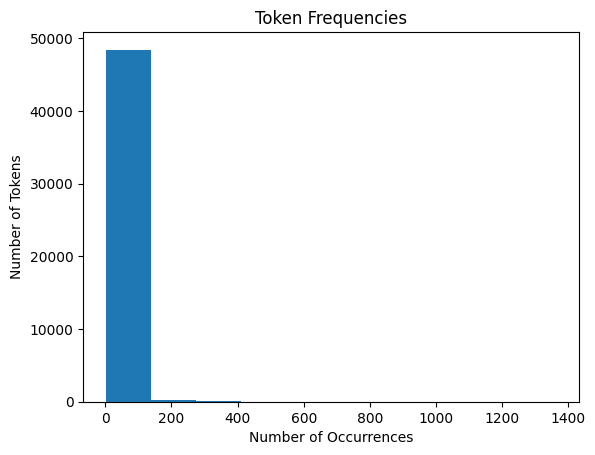

In [6]:
import matplotlib.pyplot as plt

plt.hist(token_count.values())
plt.xlabel("Number of Occurrences")
plt.ylabel("Number of Tokens")
plt.title("Token Frequencies")
plt.show()

#The histogram is right-skewed. Most tokens occur a few time and a small number of tokens occur very frequently.
#This shows that frequencies are not evenly distributed.

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

In [8]:
#Question 2.1

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

df = pd.read_parquet("Phishing_clean.parquet")

X = df.drop(columns=["Email Type"])
y = df["Email Type"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [10]:
#Question 2.2

model = LinearRegression()
model.fit(X_train, y_train)

print("Test R^2:", model.score(X_test, y_test))
print("Training R^2:", model.score(X_train, y_train))

Test R^2: 0.6658718438847919
Training R^2: 0.7670143724934355


In [13]:
#Question 2.3

coefficients = pd.Series(model.coef_, index=X.columns)
print(coefficients.abs().sort_values(ascending=False).head(10))

#The words with the largest coefficients in absolute value are “intervention,” “localized,” “thermal,” “crawler,” and “background-image:”.
#These words have the strongest influence on the model’s predictions.
#Since all the coefficients shown are positive, they help the model predict that an email is a scam.

intervention         1.259257
localized            0.824350
thermal              0.747006
crawler              0.696167
background-image:    0.622909
helvetica,           0.598560
aging                0.594956
form.                0.576886
gray;                0.574480
a:active             0.574480
dtype: float64


**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

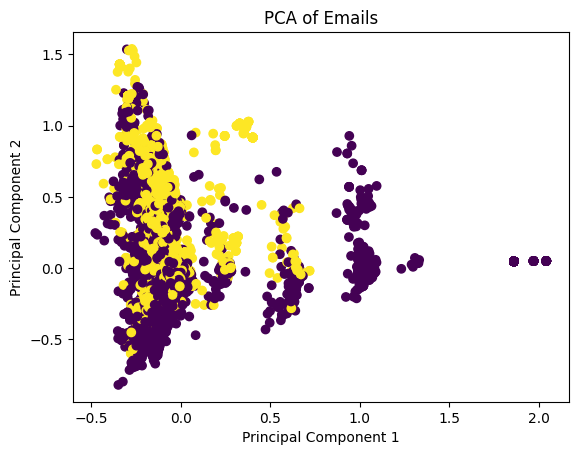

In [14]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

X = df.drop(columns=["Email Type"])
y = df["Email Type"]

pca = PCA(n_components=2)
components = pca.fit_transform(X)

plt.scatter(components[:, 0], components[:, 1], c=y)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA of Emails")
plt.show()

#The two types of emails overlap a lot, especially in the cluster on the left.
#There are some areas with mostly one type of email, but overall, the first two principal components do not separate phishing emails from non phishing emails.

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

In [15]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression

pca = PCA(n_components=2610)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

model_pca = LinearRegression()
model_pca.fit(X_train_pca, y_train)

print("Training R^2:", model_pca.score(X_train_pca, y_train))
print("Test R^2:", model_pca.score(X_test_pca, y_test))

#The PCA regression had a training R^2 of 0.766 and a test R^2 of 0.668.
#Compared to the original linear regression, the performance is almost identical.
#The PCA model has a little bit lower training R^2 but a slightly higher test R^2, so it performs around the same.

Training R^2: 0.7662326827745849
Test R^2: 0.6683390643101164


**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

In [ ]:
#Using principal components makes the data less complex by combining related features into fewer variables.
#This makes the regression more efficient and can reduce noise, and it still gives almost the same prediction accuracy as using the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Jhanvi

**Date:** 10/21/2026

In [ ]:
# Your Phase 1 solution to the problem goes here.


In [ ]:
#Answered by the questions

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]